In [1]:
# Setup. Everything below runs the CLI itself, so the notebook and the PBS job
# execute identical code.
import logging
import os
import sys

for _candidate in [".", "..", "../.."]:  # noqa: B007
    _p = os.path.abspath(_candidate)
    if os.path.isdir(os.path.join(_p, "src")):
        sys.path.insert(0, _p)
        break

from IPython.display import Image, Markdown, display  # noqa: E402

from scripts.run_corrca_condition_comparison import _build_arg_parser, run  # noqa: E402
from src.definitions.constants import ProjectPaths  # noqa: E402

logging.basicConfig(
    level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True
)
print("Setup complete.")

Setup complete.


# Stage 06b — CorrCA across conditions (joined separate)

Runs CorrCA on Placebo and Psilocybin pooled on the **subject** axis: every recording is one subject, all of them projected through **one** shared channel filter per component. Each recording keeps its own forward topography, so the topography grids contrast the conditions; the synchrony report gives each component's ISC within each condition.

**The method is documented in
[`docs/analyses/06b-corrca-condition-comparison/`](../../docs/analyses/06b-corrca-condition-comparison/README.md)** — this
notebook does not restate it.

**What this notebook is for.** Choosing parameters and checking the workflow cheaply
before committing a node to it. It calls `run()` from
[`scripts/run_corrca_condition_comparison.py`](../../scripts/run_corrca_condition_comparison.py) — the same function the PBS job
calls — at reduced scale, then shows what it wrote.

## Configuration

In [2]:
# The decomposition to run. Small on purpose -- the full-size run is the job's.
EXPERIMENT = "assr"
N_PCA = 10  # pooled covariance subspace = number of components
GAMMA = 0.0  # covariance shrinkage; 0 relies on the N_PCA truncation
# None = broadband. (30, 50) = the gamma-band run of the *_gamma.pbs jobs: the
# frequency axis is cut BEFORE the fit, and figures land under bands/ as 30-50hz_*.
BAND_RANGE = None

# Subset every axis that can be subset. Channels and pairs are what make this cheap;
# the wavelet transform itself is reused from the cache rather than recomputed.
N_PAIRS = 6  # participants
N_CHANNELS = 32  # the ASSR mask needs --lenient_mask at this width
N_TIMES = 3000  # samples (~12 s at 250 Hz)

OUT_DIR = (
    ProjectPaths.NOTEBOOKS_DIR
    / "06b-corrca-condition-comparison"
    / "out"
    / "joined_separate"
)
PLOTS_DIR = OUT_DIR / "plots"

## Run

The same function the PBS job calls. Keep the scale small here: the full-size pass is what
[`jobs/metacentrum/06b-corrca-condition-comparison/`](../../jobs/metacentrum/06b-corrca-condition-comparison) is for.
The per-condition ISC of every component is logged; the tables land beside the figures.

In [3]:
args = _build_arg_parser().parse_args(
    [
        "--experiment",
        EXPERIMENT,
        "--n_pca",
        str(N_PCA),
        "--gamma",
        str(GAMMA),
        *(["--band_range", *map(str, BAND_RANGE)] if BAND_RANGE else []),
        "--n_pairs",
        str(N_PAIRS),
        "--n_channels",
        str(N_CHANNELS),
        "--n_times",
        str(N_TIMES),
        "--reuse_wavelets",
        "--lenient_mask",  # a 32-channel subset drops most ASSR electrodes
        "--save_dir",
        str(PLOTS_DIR),
    ]
)
run(args)

INFO scripts.run_corrca_condition_comparison: CorrCA condition comparison: experiment=assr, conditions=['Placebo', 'Psilocybin'], music_types=['ASSR'], n_pca=10, gamma=0.0
INFO scripts.run_corrca_condition_comparison: === ASSR ===
INFO src.preprocessing.stimulus_alignment: Loaded per-recording stimulus-marker offsets for 38 assr recording(s); recordings without an entry fall back to -0.4245 s.
INFO src.analysis.summary.EEGSummarizedAnalyzer: Data loaded from /auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/concatenated/Placebo_ASSR.npy  (shape=(15, 195, 46980))
INFO src.analysis.summary.EEGSummarizedAnalyzer: Stimulus onsets loaded from /auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/concatenated/Placebo_ASSR.stimulus_onsets.npy (148 onsets).
INFO src.analysis.summary.EEGSummarizedAnalyzer: Metadata loaded from /auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/concatenated/Placebo_ASSR.metadata.csv


Opening raw data file /auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/cropped/PSI031_EEGA_ASSR_FAM_2_EC_20180605_122605.fif...
    Range : 3297 ... 191217 =      3.297 ...   191.217 secs
Ready.


/auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/src/io/loading.py:116: RuntimeWarning: This filename (/auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/cropped/PSI031_EEGA_ASSR_FAM_2_EC_20180605_122605.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  return mne.io.read_raw_fif(
INFO scripts.analysis_common: [Placebo_ASSR] Loaded data shape: (15, 195, 46980)
INFO scripts.analysis_common: [Placebo_ASSR] AnalysisData('Placebo_ASSR', time_domain, 15 items × 195 features × 46980 samples, sfreq=250.0)
INFO scripts.analysis_common: [Placebo_ASSR] read (15, 32, 50, 3000) from /auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/wavelets/Placebo_ASSR
INFO scripts.notebook_helpers: [Placebo_ASSR] (15, 32, 50, 3000), 15 participant(s).
INFO src.analysis.summary.EEGSummar

Opening raw data file /auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/cropped/PSI023_EEGB_ASSR_FAM_2_EC_20171222_112815.fif...
    Range : 2775 ... 190695 =      2.775 ...   190.695 secs
Ready.


/auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/src/io/loading.py:116: RuntimeWarning: This filename (/auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/cropped/PSI023_EEGB_ASSR_FAM_2_EC_20171222_112815.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  return mne.io.read_raw_fif(
INFO scripts.analysis_common: [Psilocybin_ASSR] Loaded data shape: (16, 195, 46980)
INFO scripts.analysis_common: [Psilocybin_ASSR] AnalysisData('Psilocybin_ASSR', time_domain, 16 items × 195 features × 46980 samples, sfreq=250.0)
INFO scripts.analysis_common: [Psilocybin_ASSR] read (16, 32, 50, 3000) from /auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/wavelets/Psilocybin_ASSR
INFO scripts.notebook_helpers: [Psilocybin_ASSR] (16, 32, 50, 3000), 16 participant(s).
INFO scripts.note

## Figures

The condition grids are drawn by the shared plotters in
[`src/visualization/iva_condition_plots.py`](../../src/visualization/iva_condition_plots.py),
the synchrony report by
[`src/visualization/corrca_plots.py`](../../src/visualization/corrca_plots.py) -- both
used by the CLI too, so what is shown here is what the job produces.

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/corrca_condition_isc.csv**

,component,condition,isc,n_subjects
0,1,Placebo,0.049423,6
1,2,Placebo,0.010620,6
2,3,Placebo,0.013471,6
3,4,Placebo,0.010776,6
4,5,Placebo,0.009048,6
5,6,Placebo,0.015930,6
6,7,Placebo,-0.010035,6
7,8,Placebo,-0.007621,6
8,9,Placebo,-0.007464,6
9,10,Placebo,0.002201,6


**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/corrca_condition_isc_test.csv**

,component,n_pairs,mean_difference,median_difference,statistic,p_value
0,1,6,-0.086928,-0.073614,0.0,0.03125
1,2,6,0.012608,0.016438,5.0,0.31250
2,3,6,0.002506,0.010509,8.0,0.68750
3,4,6,-0.010998,-0.014644,5.0,0.31250
4,5,6,-0.014094,-0.008542,7.0,0.56250
5,6,6,-0.037601,-0.038048,1.0,0.06250
6,7,6,0.021073,0.013641,5.0,0.31250
7,8,6,0.003074,0.002684,8.0,0.68750
8,9,6,0.003387,0.001165,9.0,0.84375
9,10,6,-0.025264,-0.013033,5.0,0.31250


**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/corrca_participant_isc.csv**

,component,condition,participant,loo_isc
0,1,Placebo,19,0.112149
1,1,Placebo,23,0.130663
2,1,Placebo,26,0.017786
3,1,Placebo,28,0.061886
4,1,Placebo,29,0.108968
...,...,...,...,...
115,10,Psilocybin,23,-0.064806
116,10,Psilocybin,26,0.003317
117,10,Psilocybin,28,-0.027014
118,10,Psilocybin,29,-0.013242


**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/condition_mean_tf_maps.png**

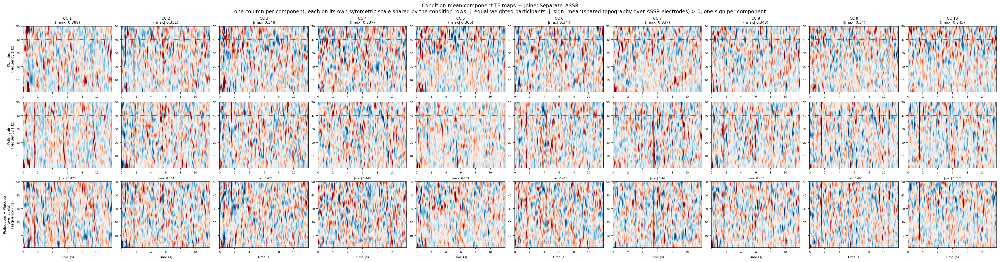

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/condition_mean_tf_maps_onset.png**

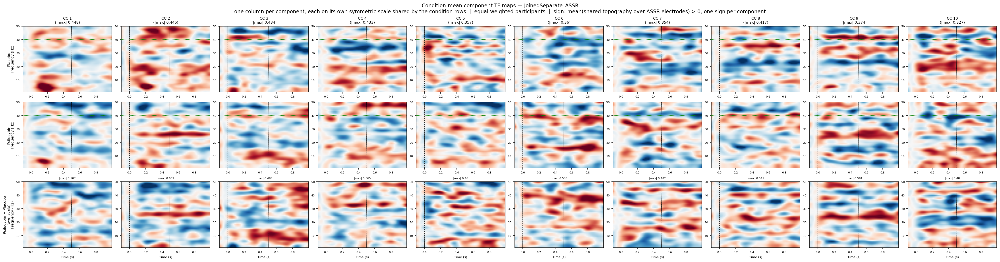

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/condition_mean_topomaps.png**

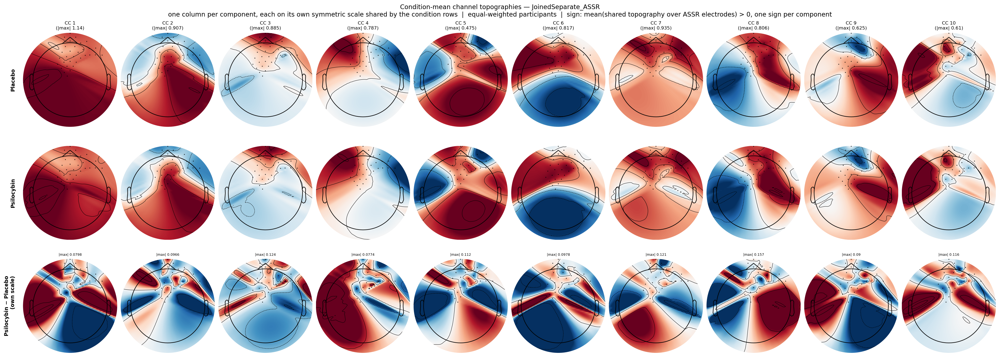

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/corrca_condition_isc.png**

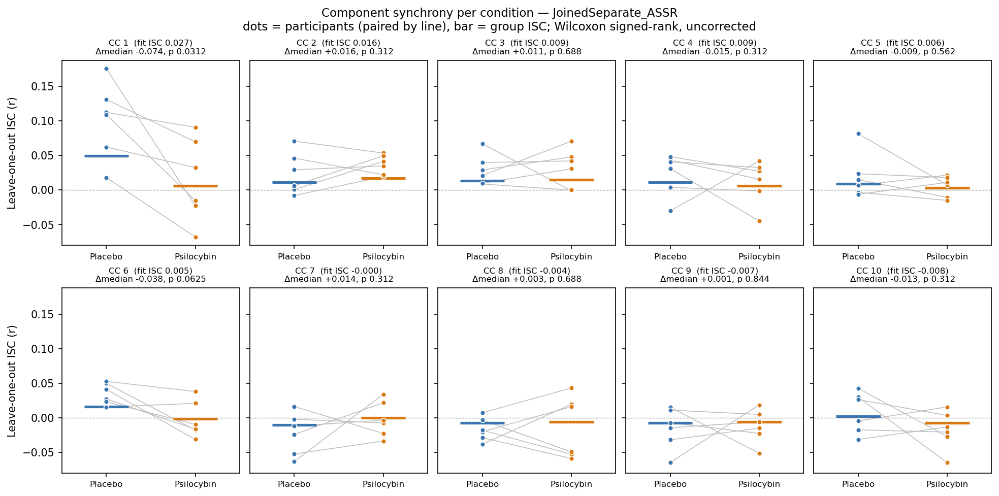

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/corrca_shared_topomaps.png**

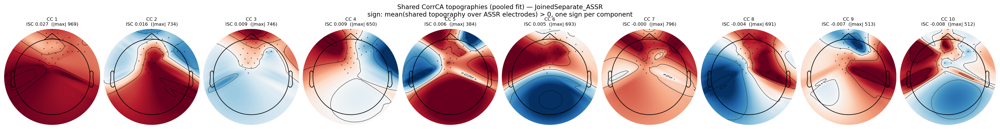

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc01_participants_JoinedSeparate_ASSR.png**

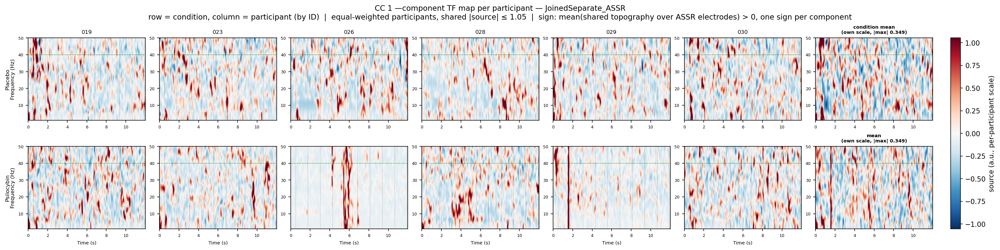

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc02_participants_JoinedSeparate_ASSR.png**

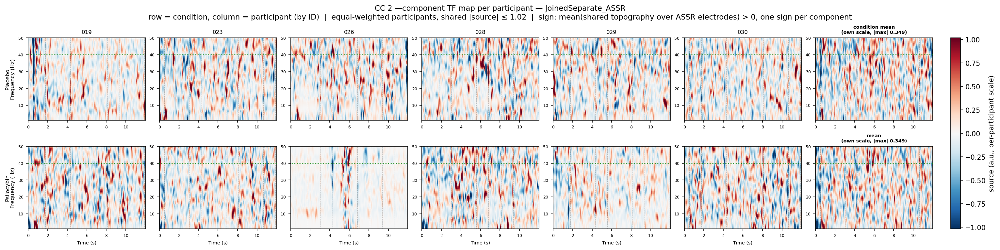

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc03_participants_JoinedSeparate_ASSR.png**

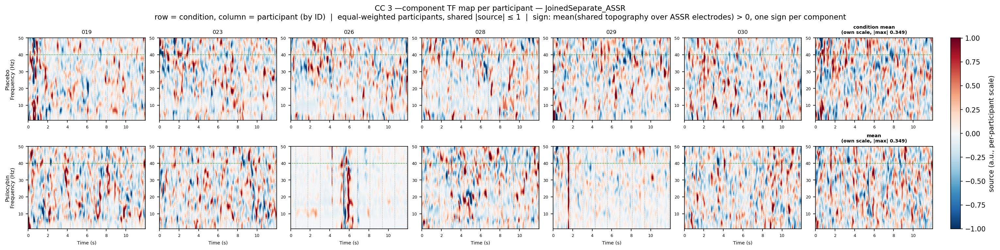

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc04_participants_JoinedSeparate_ASSR.png**

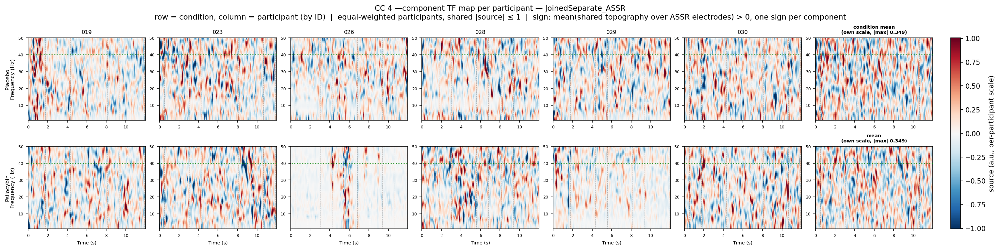

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc05_participants_JoinedSeparate_ASSR.png**

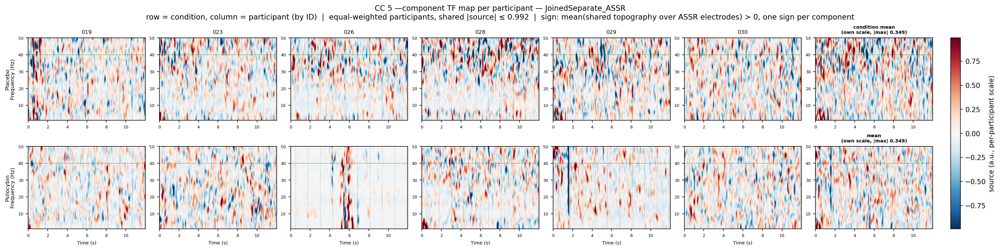

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc06_participants_JoinedSeparate_ASSR.png**

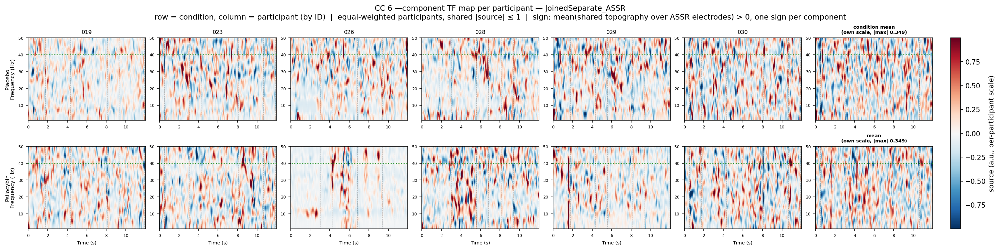

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc07_participants_JoinedSeparate_ASSR.png**

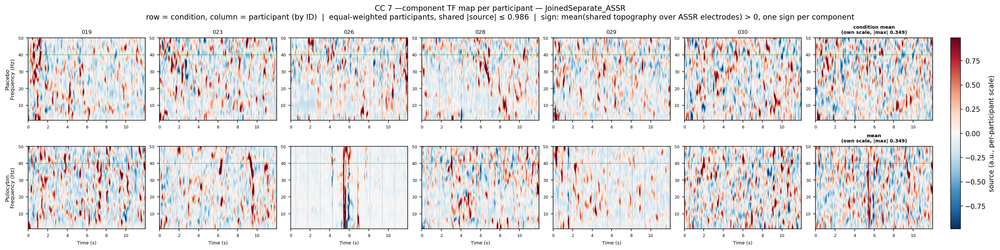

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc08_participants_JoinedSeparate_ASSR.png**

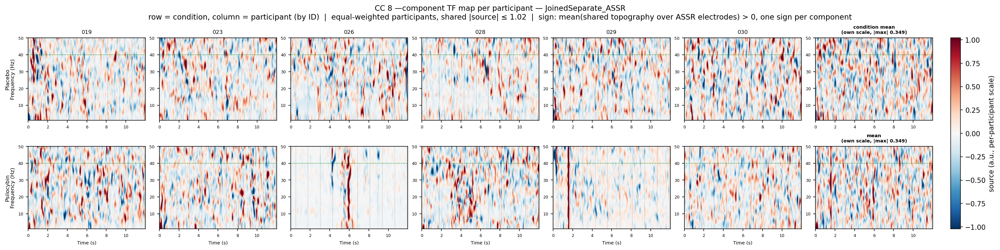

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc09_participants_JoinedSeparate_ASSR.png**

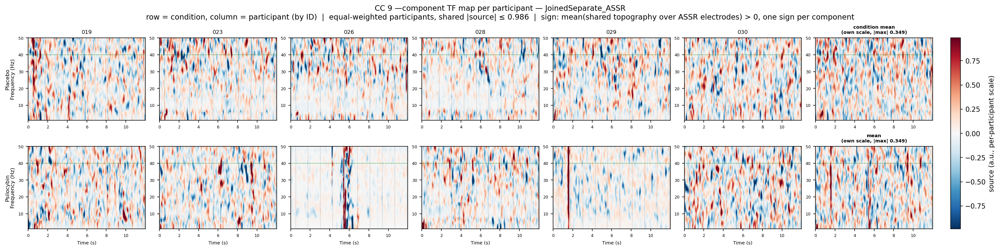

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_tf_cc10_participants_JoinedSeparate_ASSR.png**

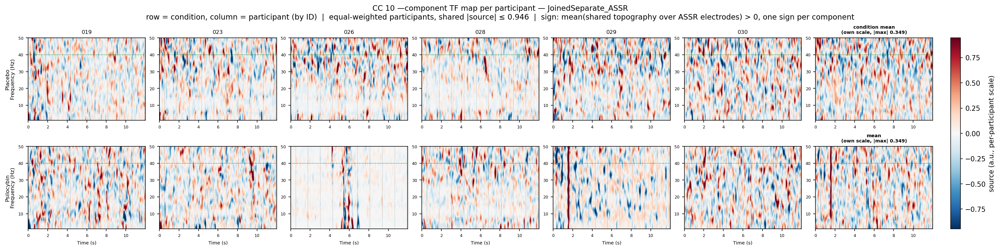

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc01_participants_JoinedSeparate_ASSR.png**

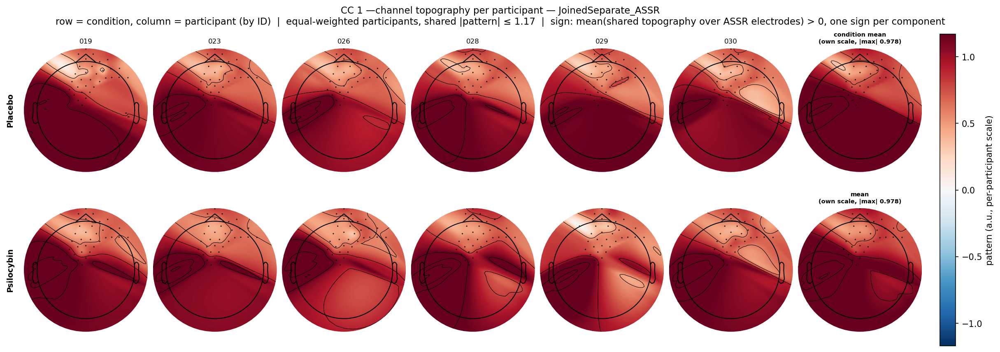

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc02_participants_JoinedSeparate_ASSR.png**

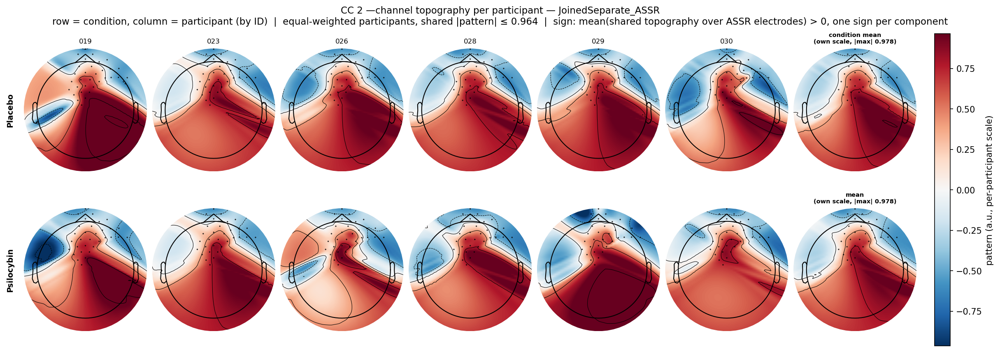

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc03_participants_JoinedSeparate_ASSR.png**

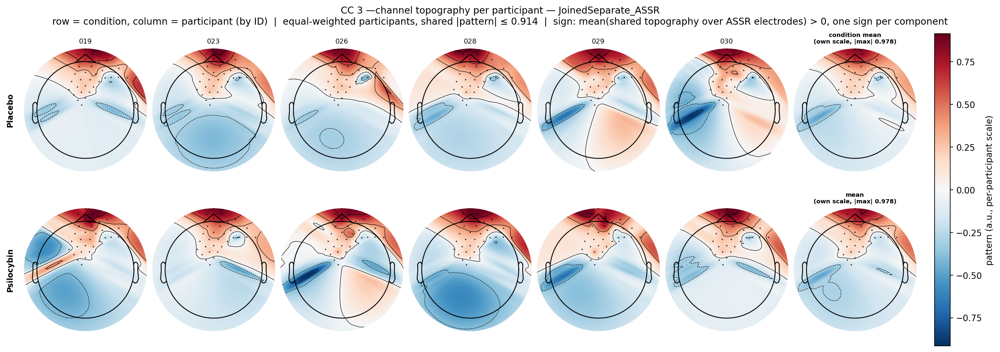

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc04_participants_JoinedSeparate_ASSR.png**

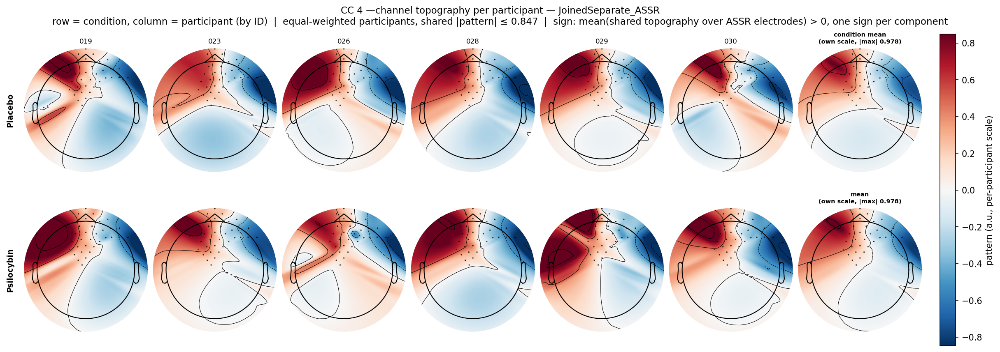

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc05_participants_JoinedSeparate_ASSR.png**

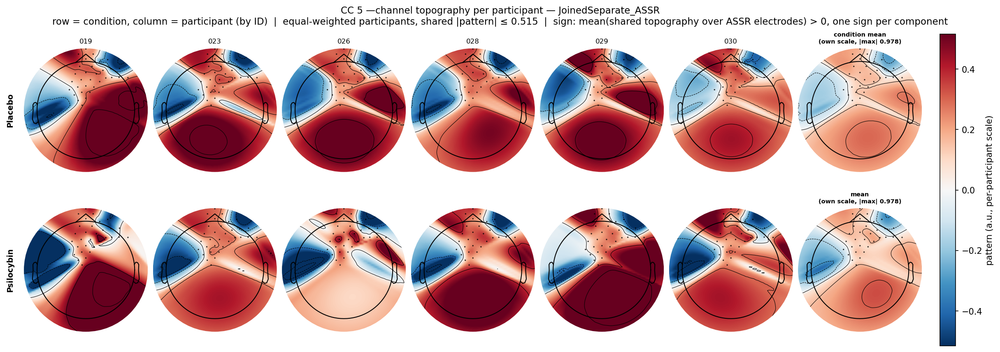

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc06_participants_JoinedSeparate_ASSR.png**

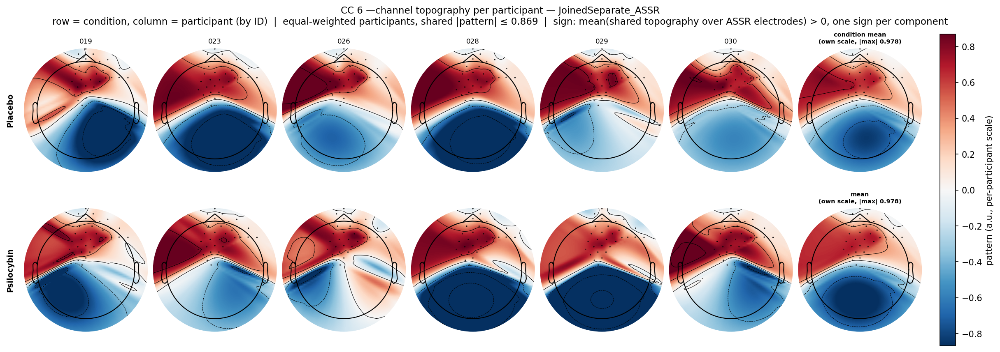

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc07_participants_JoinedSeparate_ASSR.png**

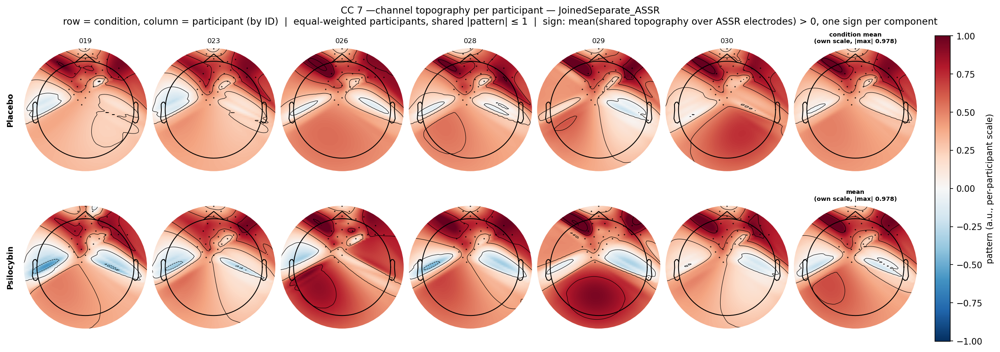

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc08_participants_JoinedSeparate_ASSR.png**

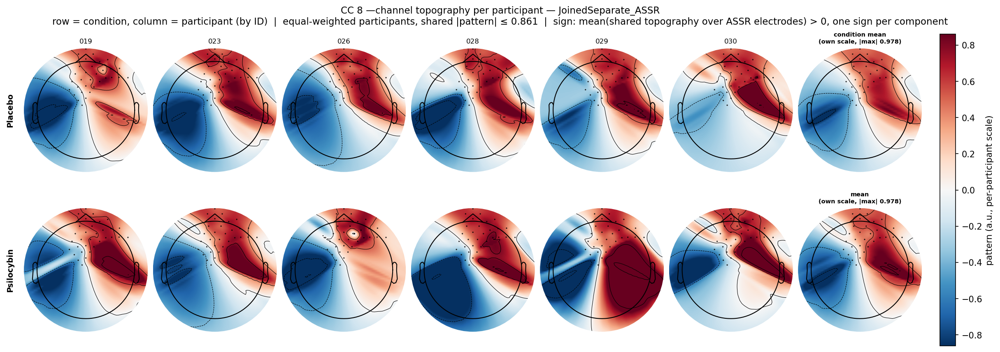

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc09_participants_JoinedSeparate_ASSR.png**

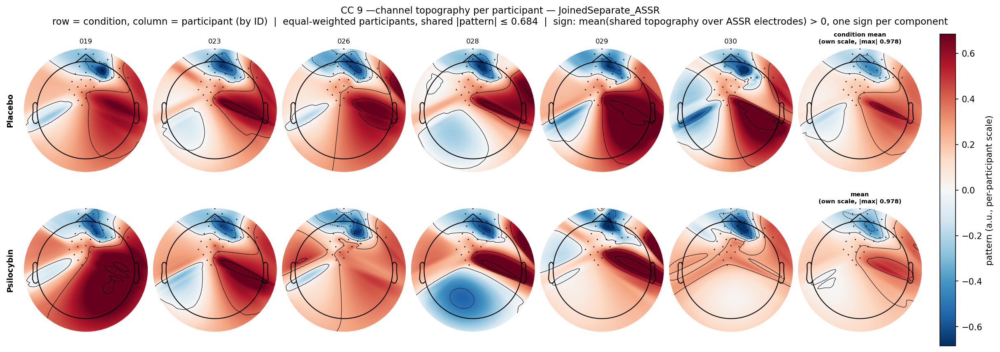

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/condition_topomap_cc10_participants_JoinedSeparate_ASSR.png**

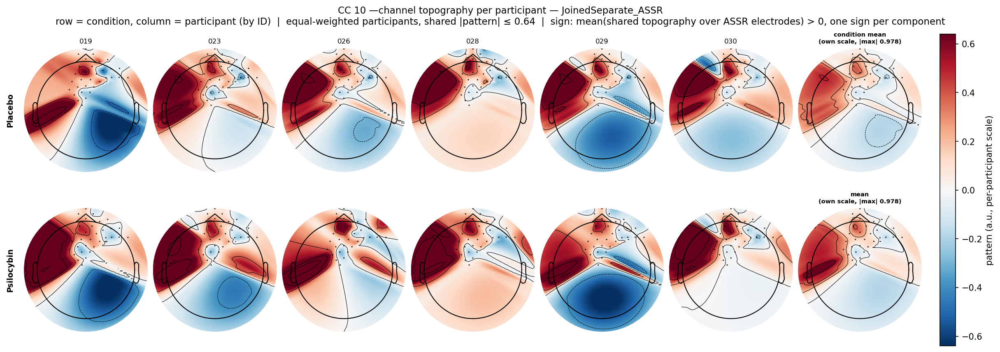

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc01_participants_JoinedSeparate_ASSR.png**

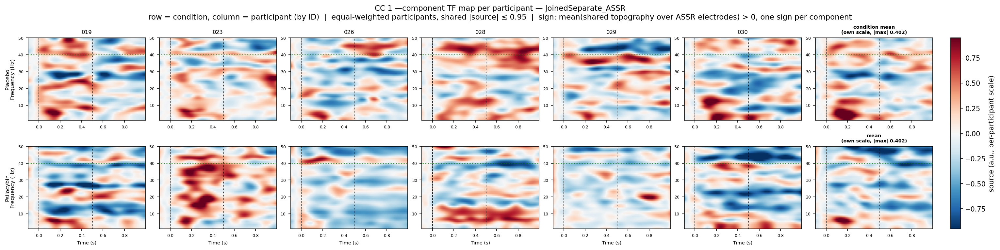

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc02_participants_JoinedSeparate_ASSR.png**

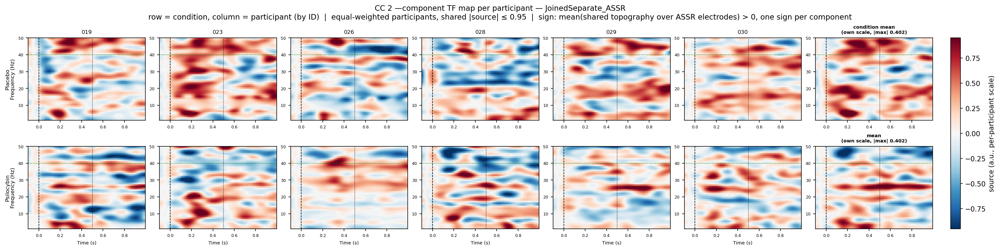

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc03_participants_JoinedSeparate_ASSR.png**

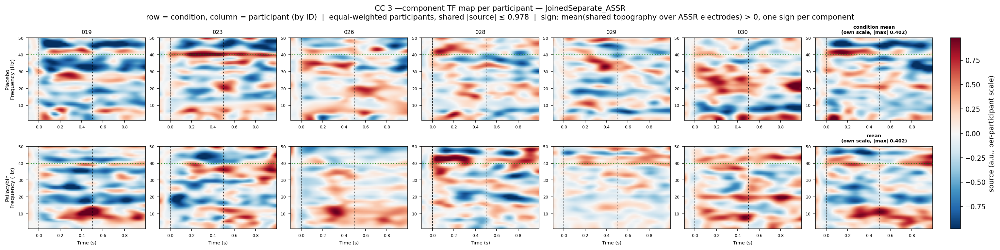

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc04_participants_JoinedSeparate_ASSR.png**

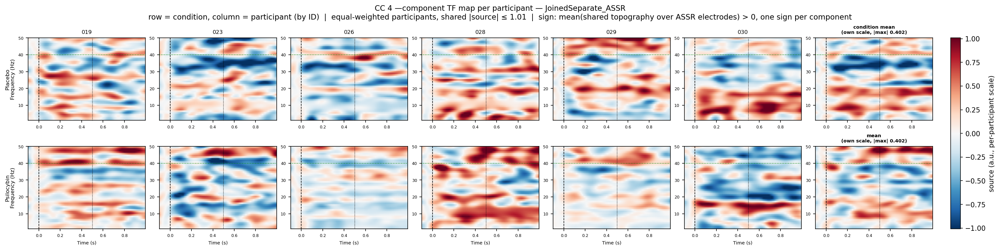

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc05_participants_JoinedSeparate_ASSR.png**

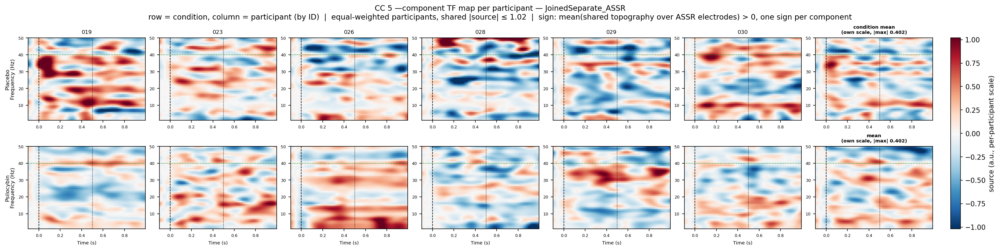

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc06_participants_JoinedSeparate_ASSR.png**

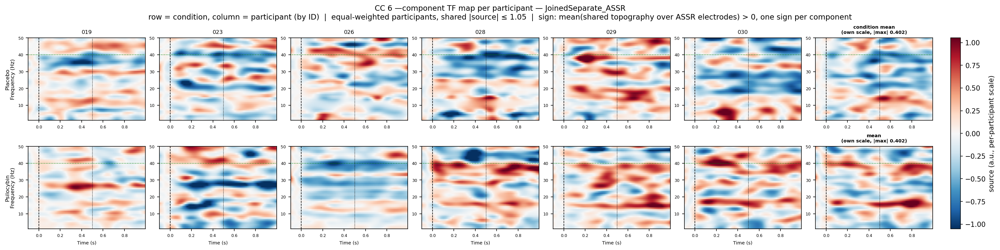

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc07_participants_JoinedSeparate_ASSR.png**

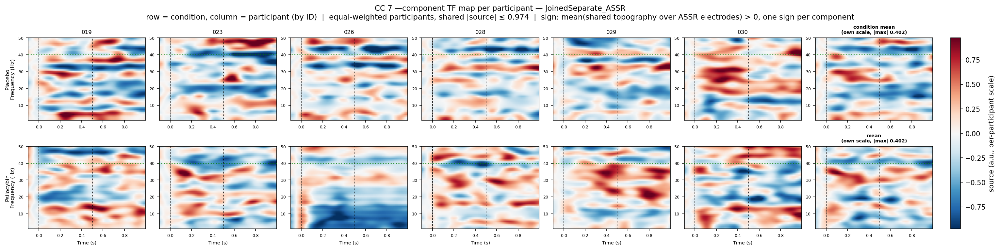

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc08_participants_JoinedSeparate_ASSR.png**

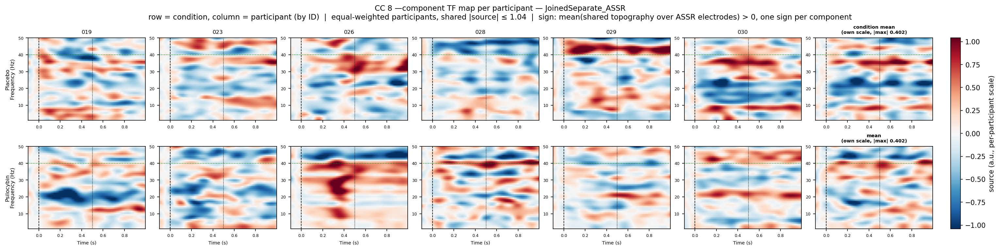

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc09_participants_JoinedSeparate_ASSR.png**

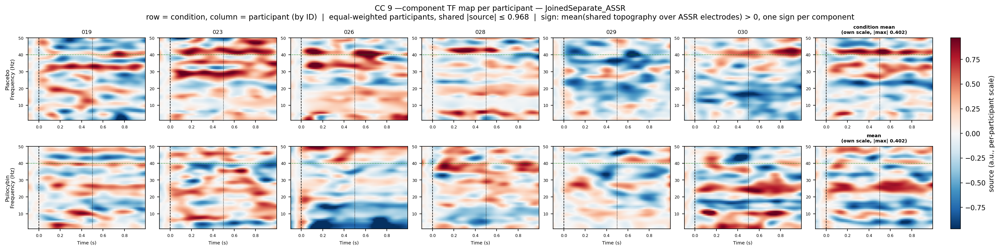

**06b-corrca-condition-comparison/JoinedSeparate_ASSR/broadband/corrca_channel_joined_separate/pca_10/participants/onset_condition_tf_cc10_participants_JoinedSeparate_ASSR.png**

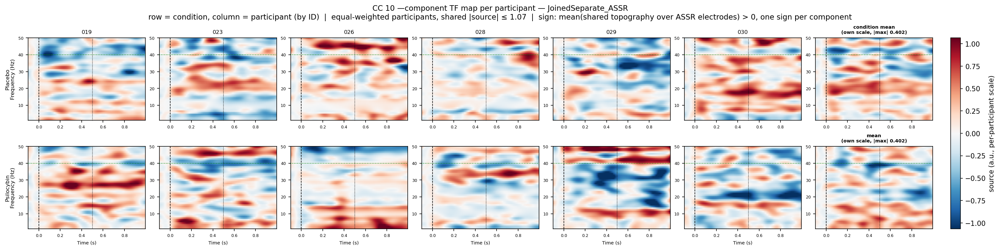

In [4]:
import pandas as pd  # noqa: E402

for csv in sorted(PLOTS_DIR.rglob("corrca_*.csv")):
    display(Markdown(f"**{csv.relative_to(PLOTS_DIR)}**"))
    display(pd.read_csv(csv))
for png in sorted(PLOTS_DIR.rglob("*.png")):
    display(Markdown(f"**{png.relative_to(PLOTS_DIR)}**"))
    display(Image(filename=str(png)))